In [29]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [30]:
path = '/jetfs/scratch/psplechtna/thesisdata/oper/2024/'
#filename_m = 'o_oper_04_tsr.nc'
#filename_g = 'oper_04_tsr.nc'

In [31]:
runs = ['01', '02', '03', '04']

In [32]:
tsr_m = xr.open_mfdataset([path+f'o_oper_{run}_tsr.nc' for run in runs])
tsr_g = xr.open_mfdataset([path+f'oper_{run}_tsr.nc' for run in runs])

In [33]:
tsr_m

<xarray.Dataset> Size: 8kB
Dimensions:       (release_date: 96)
Coordinates:
  * release_date  (release_date) datetime64[ns] 768B 2024-06-01 ... 2024-07-1...
Data variables:
    diag          (release_date) float32 384B dask.array<chunksize=(24,), meta=np.ndarray>
    diag_anomaly  (release_date) float32 384B dask.array<chunksize=(24,), meta=np.ndarray>
    init          (release_date) float64 768B dask.array<chunksize=(24,), meta=np.ndarray>
    init_anomaly  (release_date) float64 768B dask.array<chunksize=(24,), meta=np.ndarray>
    flux_lh       (release_date) float32 384B dask.array<chunksize=(24,), meta=np.ndarray>
    flux_sh       (release_date) float32 384B dask.array<chunksize=(24,), meta=np.ndarray>
    sw_rad        (release_date) float64 768B dask.array<chunksize=(24,), meta=np.ndarray>
    lw_rad        (release_date) float64 768B dask.array<chunksize=(24,), meta=np.ndarray>
    advection     (release_date) float32 384B dask.array<chunksize=(24,), meta=np.ndarray>
    seasonality   (release_date) float32 384B dask.array<chunksize=(24,), meta=np.ndarray>
    calc          (release_date) float64 768B dask.array<chunksize=(24,), meta=np.ndarray>
    calc_wo       (release_date) float64 768B dask.array<chunksize=(24,), meta=np.ndarray>

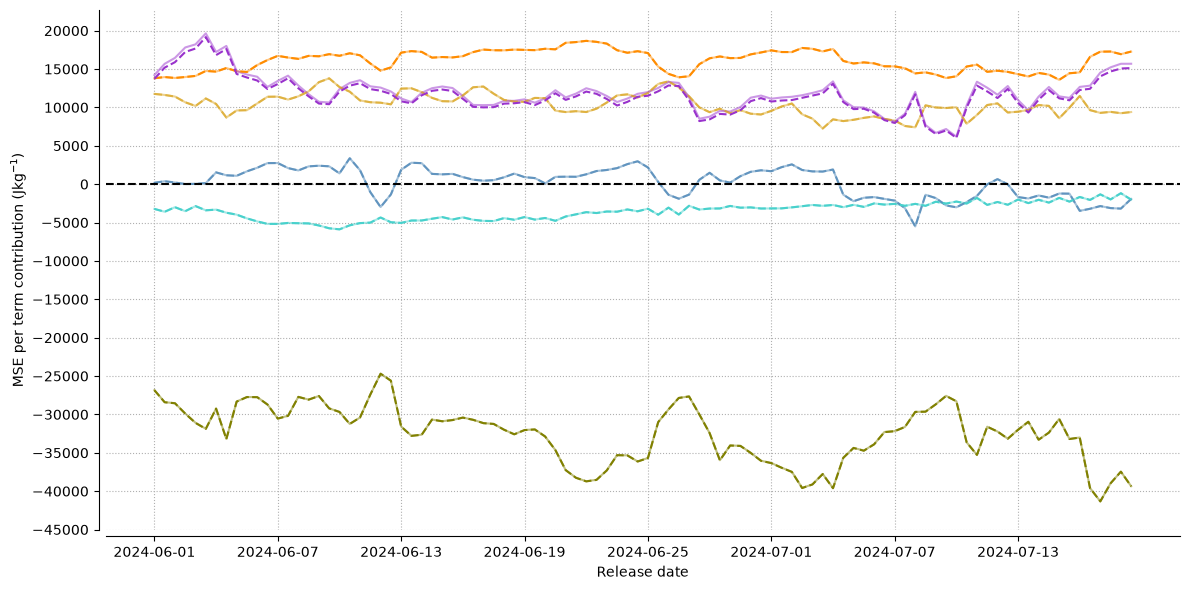

In [35]:
# single terms
xes = tsr_m.release_date

fig, ax = plt.subplots(1, 1, figsize=(12,6))

int_f_lh, = ax.plot(xes, tsr_m.flux_lh, color='goldenrod', alpha=0.5, 
                    linestyle='-', label='LH term from sfc fluxes')
int_f_sh, = ax.plot(xes, tsr_m.flux_sh, color='steelblue', alpha=0.5, 
                    linestyle='-', label='LH term from sfc fluxes')

int_s_rad, = ax.plot(xes, tsr_m.sw_rad, color='darkorange', label='SW radiation', alpha=0.5)
int_l_rad, = ax.plot(xes, tsr_m.lw_rad, color='olive', label='LW radiation', alpha=0.5)
int_adve, = ax.plot(xes, tsr_m.advection, color='darkorchid', label='Advection', alpha=0.5)
int_s, = ax.plot(xes, tsr_m.seasonality, color='mediumturquoise', label='Seasonality', alpha=0.5)

ax.plot(xes, tsr_g.flux_lh, color='goldenrod', alpha=0.7, linestyle='--',
                    label='LH term from sfc fluxes')
ax.plot(xes, tsr_g.flux_sh, color='steelblue', alpha=0.7, linestyle='--',
                    label='LH term from sfc fluxes')

ax.plot(xes, tsr_g.sw_rad, color='darkorange', label='SW radiation', linestyle='--')
ax.plot(xes, tsr_g.lw_rad, color='olive', linestyle='--', label='LW radiation')
ax.plot(xes, tsr_g.advection, color='darkorchid', linestyle='--', label='Advection')
ax.plot(xes, tsr_g.seasonality, color='mediumturquoise', linestyle='--', label='Seasonality')

ax.set_ylabel('MSE per term contribution (Jkg$^{-1}$)')
ax.set_xticks(xes[::12])
ax.set_xlabel('Release date')

#ax.set_ylim(-46000, 22000)
ax.set_yticks(np.arange(-45000, 21000, 5000))

ax.axhline(0, linestyle='--', color='k')

# make prettier
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))
ax.grid(linestyle=':')

fig.tight_layout()
#fig.savefig('allterms.png')